# Beef Cold-Storage Signal

## Monthly long–short backtest

**Year-end results:** using dividend-adjusted prices through December 2025, the two-month signal has a **0.341 Sharpe** over July 2007–December 2025 and a **0.668 Sharpe** over January 2017–December 2025. For context, the same recent window is **0.634** through June and **0.600** through September 2025; all three endpoints are shown below.

This notebook explains the signal, its walk-forward evaluation, and the matched comparison with the BotQ equal-weight stock basket. The BotQ universe comparison ends in September 2025; a clearly labeled final section extends the signal itself through December using public adjusted prices for TSN, CPB, and GIS.


## 1. Signal idea and portfolio

USDA beef cold-storage inventory measures beef held in cold storage. A year-over-year change can capture a shift in available supply or demand conditions. That information may affect meat prices, processor margins, and Tyson Foods’ outlook, but the direction is not obvious in advance: more inventory can mean plentiful supply, weak demand, or both. The model estimates the historical relationship instead of hard-coding a positive or negative effect.

The feature is the **12-month percentage change** in cold-storage inventory. An expanding one-feature regression forecasts the one-month return of Tyson Foods (TSN) relative to an equal-weight Campbell’s (CPB) and General Mills (GIS) basket **two months after the observation month**. We assume a one-month delay before monthly inventory data is available.

When the forecasted relative return is positive, the example portfolio is 50% long TSN and 25% short each of CPB and GIS; when negative, it reverses. This dollar-neutral, 100%-gross long–short position expresses the relative forecast and reduces broad equity exposure. It does not guarantee zero market beta, and the packaged-food controls are imperfect matches for Tyson.

## 2. Data and processing

- **Cold storage:** USDA beef cold-storage inventory, in millions of pounds, supplied as a monthly CSV. We calculate the percent change from the same month one year earlier.
- **Stocks:** the BotQ export contains daily stock returns in percentage points. It is CSV text despite its `.parquet` filename. This repository does not redistribute the competition export or the compact panel derived from it. The preparation script documents the monthly compounding process for an authorized export.
- **Broad comparison:** each month, the benchmark equally weights the available BotQ stock-month returns. The source panel keeps stocks with at least 15 valid daily observations and drops the incomplete final month. This is an equal-weight Russell-universe proxy, not the official market-cap-weighted Russell 3000 index.
- **Year-end extension:** public Yahoo Finance dividend-adjusted prices are converted to monthly returns for TSN, CPB, and GIS. These provide October–December 2025, which are absent from the BotQ export. Their overlapping pair returns are checked against BotQ before the signal is extended.

The original 1.7 GB daily export and the derived stock-month panel are omitted from this public package. If your competition access terms permit local use, the included preparation script converts an authorized export to the compact monthly panel needed for the BotQ comparison.


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = Path.cwd()
CANDIDATES = [HERE, *(p / "botq_final_submission" for p in [HERE, *HERE.parents])]
ROOT = next((p for p in CANDIDATES if (p / "data" / "botq_monthly_stock_returns.csv.gz").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from botq_final_submission, which contains the data folder.")
DATA = ROOT / "data"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
print(f"Submission folder: {ROOT}")

cold = pd.read_csv(DATA / "cattle_beef_cold_storage_monthly.csv", parse_dates=["month"])
cold["month"] = cold["month"].dt.to_period("M")
cold["cold_storage_million_lb"] = pd.to_numeric(cold["cold_storage_million_lb"], errors="coerce")
cold = cold.drop_duplicates("month").set_index("month").sort_index()
feature = cold["cold_storage_million_lb"].pct_change(12).rename("cold_storage_yoy").to_frame().dropna()
print(f"Cold-storage observations: {cold.index.min()} to {cold.index.max()}")
print(f"Year-over-year feature: {feature.index.min()} to {feature.index.max()}")

Submission folder: project root
Cold-storage observations: 1917-02 to 2026-10
Year-over-year feature: 1918-02 to 2026-10


## 3. Monthly stock returns and benchmarks

The positive-direction pair return is 50% TSN minus 50% of the CPB/GIS basket. The signal reverses that pair when its forecast is negative. The market comparison is formed from all monthly stocks in the BotQ panel, not from a raw sum: averaging equal-weight constituents keeps the result on the scale of a portfolio return.

In [6]:
stock_monthly = pd.read_csv(DATA / "botq_monthly_stock_returns.csv.gz")
stock_monthly["month"] = pd.PeriodIndex(stock_monthly["month"], freq="M")
stock_monthly = stock_monthly.loc[stock_monthly["days"] >= 15].copy()

universe = stock_monthly.groupby("month").agg(
    universe_return=("monthly_return", "mean"),
    stocks_in_universe=("barrid", "nunique"),
)
universe.index = pd.PeriodIndex(universe.index, freq="M")

targets = ["TSN", "CPB", "GIS"]
pair_stocks = stock_monthly.loc[stock_monthly["ticker"].isin(targets)].copy()
if pair_stocks.duplicated(["month", "ticker"]).any():
    raise ValueError("Target ticker appears more than once in a month; inspect the BarrID mapping.")
returns = pair_stocks.pivot(index="month", columns="ticker", values="monthly_return").sort_index()
missing = sorted(set(targets) - set(returns.columns))
if missing:
    raise ValueError(f"Missing target stocks: {missing}")

food_basket = returns[["CPB", "GIS"]].mean(axis=1, skipna=False)
pair_return = (0.5 * (returns["TSN"] - food_basket)).rename("TSN_vs_food_pair")
print(f"BotQ monthly returns: {stock_monthly.month.min()} to {stock_monthly.month.max()}")
print(f"Available stocks per month: {universe.stocks_in_universe.min():,}–{universe.stocks_in_universe.max():,}; median {universe.stocks_in_universe.median():,.0f}")

BotQ monthly returns: 2000-01 to 2025-09
Available stocks per month: 2,697–3,153; median 2,952


## 4. Point-in-time walk-forward model

The model is refit each month using an expanding history. It requires 60 matured training outcomes, and a training outcome is eligible only after its two-month-ahead return has occurred by the assumed information date. The return assigned to each position is the relative pair’s one-month return in the forecast target month.

In [8]:
def walk_forward_ols(features, pair_returns, horizon_months, min_train=60):
    future_target = pair_returns.shift(-horizon_months)
    frame = features.join(future_target.rename("future_pair_return"), how="inner").dropna()
    frame["target_month"] = [month + horizon_months for month in frame.index]
    rows = []
    for signal_month, current in frame.iterrows():
        info_available_month = signal_month + 1  # publication-delay assumption
        history = frame[(frame.index < signal_month) & (frame["target_month"] < info_available_month)]
        if len(history) < min_train:
            continue
        x_train = history[features.columns].to_numpy(dtype=float)
        x_now = current[features.columns].to_numpy(dtype=float)
        mean, sd = x_train.mean(axis=0), x_train.std(axis=0, ddof=0)
        sd[sd == 0] = 1.0
        design = np.column_stack([np.ones(len(history)), (x_train - mean) / sd])
        beta = np.linalg.lstsq(design, history["future_pair_return"].to_numpy(dtype=float), rcond=None)[0]
        forecast = float(np.r_[1.0, (x_now - mean) / sd] @ beta)
        rows.append({
            "signal_month": signal_month,
            "target_month": signal_month + horizon_months,
            "actual_pair_return": float(current["future_pair_return"]),
            "forecast": forecast,
            "training_months": len(history),
        })
    return pd.DataFrame(rows).set_index("target_month").sort_index()

def performance(r):
    r = pd.Series(r, dtype=float).dropna()
    wealth = (1 + r).cumprod()
    peaks = np.maximum.accumulate(np.r_[1.0, wealth.to_numpy()])[1:]
    return pd.Series({
        "months": len(r),
        "total_return": wealth.iloc[-1] - 1,
        "annualized_return": wealth.iloc[-1] ** (12 / len(r)) - 1,
        "annualized_volatility": r.std(ddof=1) * np.sqrt(12),
        "sharpe_rf0": r.mean() / r.std(ddof=1) * np.sqrt(12),
        "max_drawdown": (wealth.to_numpy() / peaks - 1).min(),
        "positive_month_share": (r > 0).mean(),
    })

COMMON_START = pd.Period("2007-07", freq="M")
COMMON_END = pd.Period("2025-09", freq="M")
MIN_TRAIN = 60
HORIZONS = [1, 2, 3]
forecasts, strategies = {}, {}
for horizon in HORIZONS:
    pred = walk_forward_ols(feature, pair_return, horizon, min_train=MIN_TRAIN)
    pred = pred.loc[(pred.index >= COMMON_START) & (pred.index <= COMMON_END)].copy()
    pred["position"] = np.where(pred["forecast"] >= 0, 1.0, -1.0)
    pred["strategy_return"] = pred["position"] * pred["actual_pair_return"]
    pred["static_pair_return"] = pair_return.reindex(pred.index)
    pred["universe_return"] = universe["universe_return"].reindex(pred.index)
    pred["stocks_in_universe"] = universe["stocks_in_universe"].reindex(pred.index)
    pred = pred.dropna(subset=["strategy_return", "static_pair_return", "universe_return"])
    forecasts[horizon] = pred
    strategies[horizon] = pred["strategy_return"].rename(f"{horizon}-month signal")

primary = forecasts[2]
primary.to_csv(RESULTS / "cold_storage_monthly_backtest.csv")
print(f"Primary test: {primary.index.min()} to {primary.index.max()} ({len(primary)} months)")
print(f"Directional hit rate: {(np.sign(primary.forecast) == np.sign(primary.actual_pair_return)).mean():.1%}")

Primary test: 2007-07 to 2025-09 (219 months)
Directional hit rate: 52.1%


## 5. Performance: matched BotQ history

This section uses the BotQ stock-return file, which ends in September 2025, so the signal, static pair, and equal-weight benchmark are compared on the same dates. The 2017–June 2025 result is the period behind the remembered 0.64 figure; extending it to September gives 0.60. Section 11 independently extends the signal to December 2025 and reports all three endpoints together.


In [10]:
periods = {
    "Full OOS: Jul 2007–Sep 2025": (primary.index >= pd.Period("2007-07", freq="M")),
    "Recent: Jan 2017–Jun 2025 (0.64 window)": (primary.index >= pd.Period("2017-01", freq="M")) & (primary.index <= pd.Period("2025-06", freq="M")),
    "Recent: Jan 2017–Sep 2025": (primary.index >= pd.Period("2017-01", freq="M")),
    "Recent: Jan 2023–Sep 2025": (primary.index >= pd.Period("2023-01", freq="M")),
}
portfolios = {
    "Cold-storage signal (long/short)": "strategy_return",
    "Static TSN vs. CPB/GIS pair": "static_pair_return",
    "BotQ equal-weight universe (long only)": "universe_return",
}
summary_rows = []
for period_name, mask in periods.items():
    selected = primary.loc[np.asarray(mask)]
    for portfolio_name, column in portfolios.items():
        row = performance(selected[column]).to_dict()
        row.update({"period": period_name, "portfolio": portfolio_name})
        summary_rows.append(row)
summary = pd.DataFrame(summary_rows).set_index(["period", "portfolio"])
summary.to_csv(RESULTS / "cold_storage_performance_summary.csv")

shown = summary.copy()
for col in ["total_return", "annualized_return", "annualized_volatility", "max_drawdown", "positive_month_share"]:
    shown[col] = shown[col].map(lambda x: f"{x:.1%}")
shown["sharpe_rf0"] = shown["sharpe_rf0"].map(lambda x: f"{x:.3f}")
shown["months"] = shown["months"].astype(int)
display(shown)

                                                                                months  ... positive_month_share
period                                  portfolio                                       ...                     
Full OOS: Jul 2007–Sep 2025             Cold-storage signal (long/short)           219  ...                52.1%
                                        Static TSN vs. CPB/GIS pair                219  ...                52.1%
                                        BotQ equal-weight universe (long only)     219  ...                61.6%
Recent: Jan 2017–Jun 2025 (0.64 window) Cold-storage signal (long/short)           102  ...                55.9%
                                        Static TSN vs. CPB/GIS pair                102  ...                51.0%
                                        BotQ equal-weight universe (long only)     102  ...                60.8%
Recent: Jan 2017–Sep 2025               Cold-storage signal (long/short)           105  ...     

## 6. Horizon comparison and transaction costs

The two-month horizon was selected in earlier exploratory work. The same walk-forward process tests one and three months for context. Because those variants were part of signal development, this comparison is not a fresh independent test. The cost table applies illustrative costs per dollar of one-way turnover; it does not model borrow availability, market impact, or financing.

In [12]:
horizon_rows = []
for horizon, pred in forecasts.items():
    row = performance(pred["strategy_return"]).to_dict()
    row["horizon_months"] = horizon
    horizon_rows.append(row)
horizon_summary = pd.DataFrame(horizon_rows).set_index("horizon_months").sort_index()
horizon_summary.to_csv(RESULTS / "cold_storage_horizon_summary.csv")
display(horizon_summary.round(3))

weights = pd.DataFrame({
    "TSN": 0.50 * primary["position"],
    "CPB": -0.25 * primary["position"],
    "GIS": -0.25 * primary["position"],
})
turnover = 0.5 * weights.diff().abs().sum(axis=1)
turnover.iloc[0] = weights.iloc[0].abs().sum()
cost_rows = []
for cost_bps in [0, 5, 10, 25]:
    net = primary["strategy_return"] - turnover * cost_bps / 10_000
    stats = performance(net)
    cost_rows.append({"one_way_cost_bps": cost_bps,
                      "mean_monthly_turnover": turnover.mean(),
                      "annualized_return": stats["annualized_return"],
                      "sharpe_rf0": stats["sharpe_rf0"],
                      "total_return": stats["total_return"]})
costs = pd.DataFrame(cost_rows).set_index("one_way_cost_bps")
costs.to_csv(RESULTS / "cold_storage_cost_sensitivity.csv")
cost_display = costs.copy()
for col in ["mean_monthly_turnover", "annualized_return", "total_return"]:
    cost_display[col] = cost_display[col].map(lambda x: f"{x:.1%}")
cost_display["sharpe_rf0"] = cost_display["sharpe_rf0"].map(lambda x: f"{x:.2f}")
display(cost_display)
print(f"Average monthly one-way turnover: {turnover.mean():.1%}")

Average monthly one-way turnover: 5.9%


                months  total_return  ...  max_drawdown  positive_month_share
horizon_months                        ...                                    
1                219.0        -0.189  ...        -0.566                 0.498
2                219.0         0.878  ...        -0.430                 0.521
3                219.0        -0.585  ...        -0.720                 0.484

[3 rows x 7 columns]

                 mean_monthly_turnover  ... total_return
one_way_cost_bps                        ...             
0                                 5.9%  ...        87.8%
5                                 5.9%  ...        86.6%
10                                5.9%  ...        85.4%
25                                5.9%  ...        81.9%

[4 rows x 4 columns]

## 7. Cumulative returns and drawdown

These matched-period plots end in September 2025 because that is the end of the complete BotQ universe data. Sharpe ratios in the legend refer to the full July 2007–September 2025 period. The portfolio and universe benchmark use different capital conventions: long–short return is per dollar of gross exposure, and the long-only benchmark is per dollar invested.


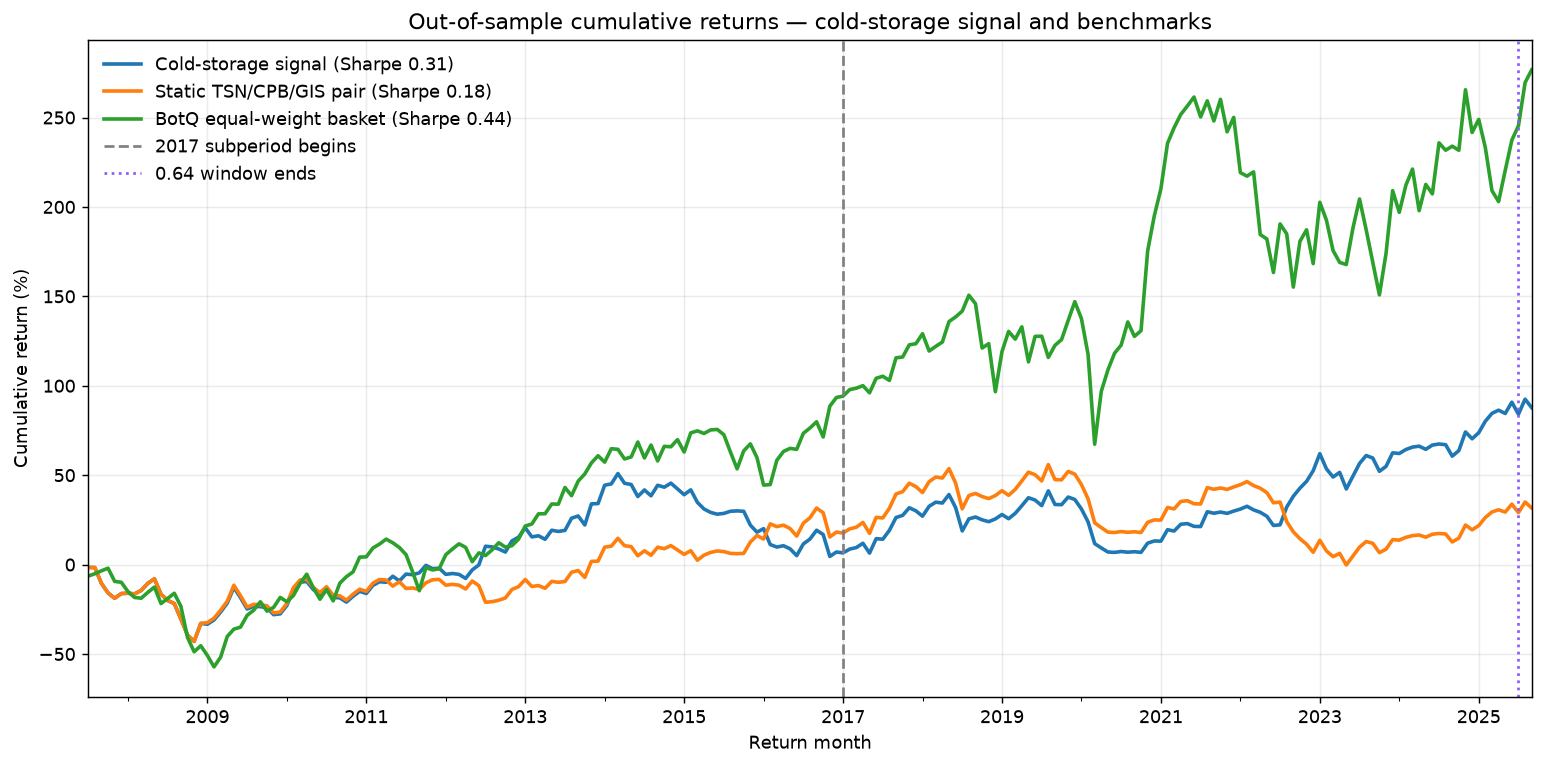

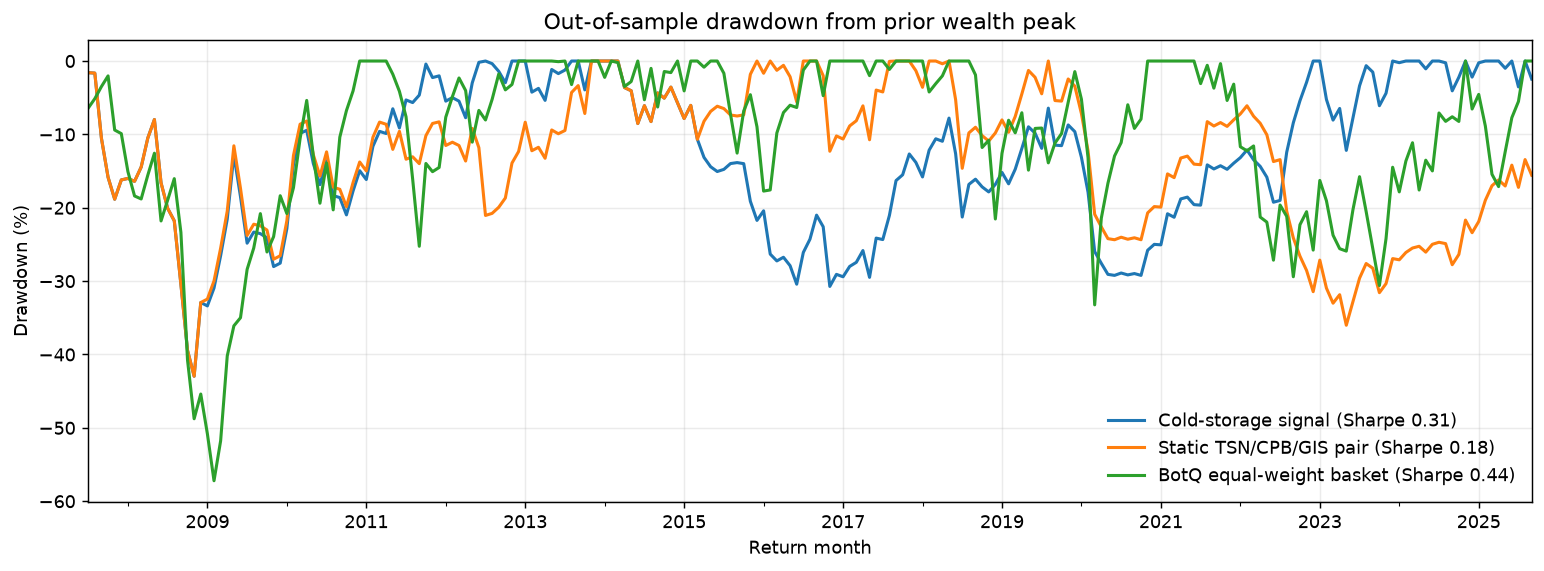

In [14]:
signal_sharpe = performance(primary["strategy_return"])["sharpe_rf0"]
pair_sharpe = performance(primary["static_pair_return"])["sharpe_rf0"]
universe_sharpe = performance(primary["universe_return"])["sharpe_rf0"]
wealth = pd.DataFrame({
    f"Cold-storage signal (Sharpe {signal_sharpe:.2f})": (1 + primary["strategy_return"]).cumprod(),
    f"Static TSN/CPB/GIS pair (Sharpe {pair_sharpe:.2f})": (1 + primary["static_pair_return"]).cumprod(),
    f"BotQ equal-weight basket (Sharpe {universe_sharpe:.2f})": (1 + primary["universe_return"]).cumprod(),
})
ax = ((wealth - 1) * 100).plot(figsize=(12, 6), linewidth=2)
ax.set_title("Out-of-sample cumulative returns — cold-storage signal and benchmarks")
ax.set_ylabel("Cumulative return (%)")
ax.set_xlabel("Return month")
ax.grid(alpha=.25)
ax.axvline(pd.Period("2017-01", freq="M").to_timestamp(), color="gray", linestyle="--", label="2017 subperiod begins")
ax.axvline(pd.Period("2025-07", freq="M").to_timestamp(), color="#8B5CF6", linestyle=":", label="0.64 window ends")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(RESULTS / "cold_storage_cumulative_returns.png", dpi=180, bbox_inches="tight")
plt.show()

wealth_start = pd.concat([pd.DataFrame([{c: 1.0 for c in wealth.columns}], index=[wealth.index.min() - 1]), wealth])
drawdown = wealth_start.div(wealth_start.cummax()).sub(1).loc[wealth.index] * 100
ax = drawdown.plot(figsize=(12, 4.5), linewidth=1.7)
ax.set_title("Out-of-sample drawdown from prior wealth peak")
ax.set_ylabel("Drawdown (%)")
ax.set_xlabel("Return month")
ax.grid(alpha=.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(RESULTS / "cold_storage_drawdowns.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Sharpe by evaluation window and calendar-year returns

This chart uses the BotQ matched sample through September 2025. Section 11 adds the December endpoint for the signal using dividend-adjusted prices, preserving June and September results for comparison.


                            Signal Sharpe
Full OOS (2007–2025)                0.310
2017–Jun 2025 (0.64 window)         0.634
2017–Sep 2025                       0.600
2023–Sep 2025                       0.716

             signal_return static_pair_return universe_return
target_month                                                 
2007                -16.2%             -16.2%           -9.9%
2008                -19.9%             -19.9%          -39.4%
2009                  8.0%               9.5%           49.5%
2010                 17.4%              17.4%           27.6%
2011                 15.2%               6.3%           -6.3%
2012                 17.7%              -4.4%           17.0%
2013                 16.3%              16.3%           40.8%
2014                  6.1%               6.1%            5.6%
2015                -17.0%               7.5%           -5.9%
2016                 -9.4%               1.7%           21.0%
2017                 21.5%              21.5%           15.6%
2018                 -3.5%              -3.5%          -12.0%
2019                  8.6%               8.6%           25.6%
2020                -17.0%             -17.0%           19.4%
2021    

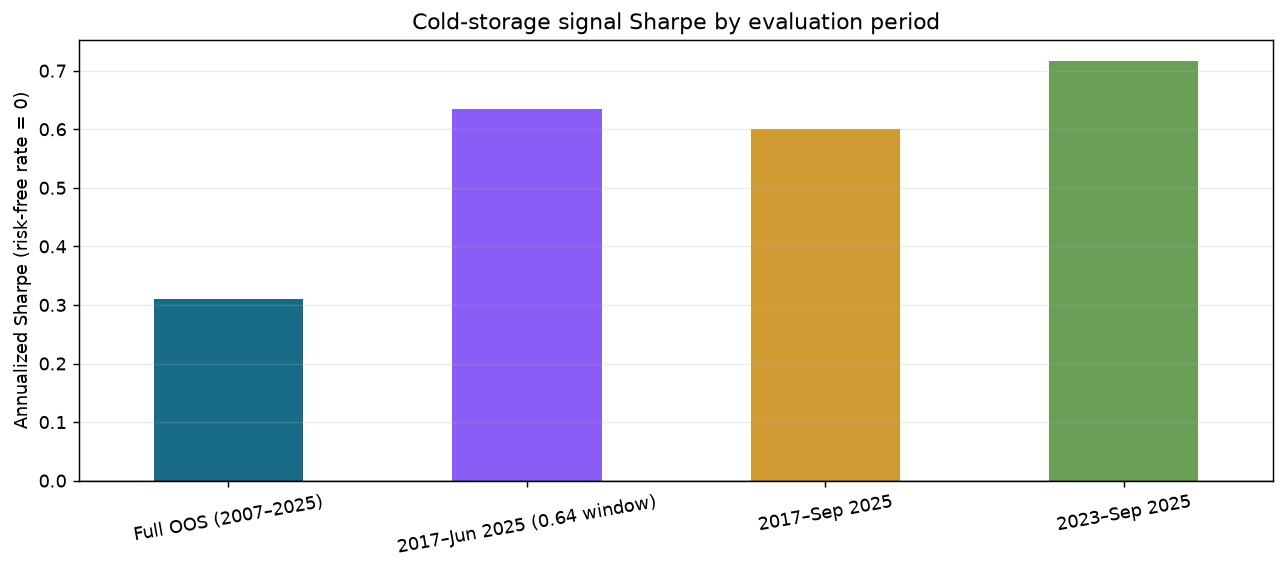

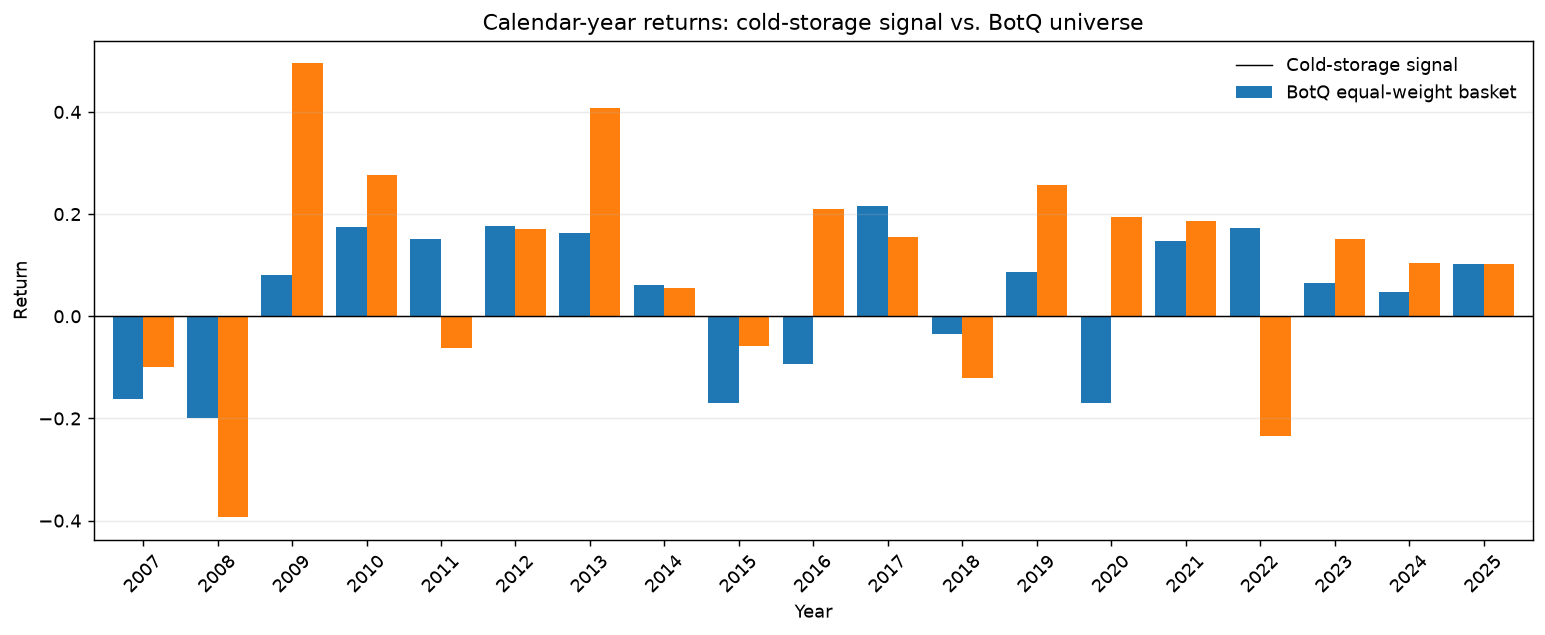

In [16]:
signal_windows = {
    "Full OOS (2007–2025)": primary["strategy_return"],
    "2017–Jun 2025 (0.64 window)": primary.loc[(primary.index >= pd.Period("2017-01", freq="M")) & (primary.index <= pd.Period("2025-06", freq="M")), "strategy_return"],
    "2017–Sep 2025": primary.loc[primary.index >= pd.Period("2017-01", freq="M"), "strategy_return"],
    "2023–Sep 2025": primary.loc[primary.index >= pd.Period("2023-01", freq="M"), "strategy_return"],
}
signal_sharpes = pd.Series({label: performance(r)["sharpe_rf0"] for label, r in signal_windows.items()})
display(signal_sharpes.map(lambda x: f"{x:.3f}").to_frame("Signal Sharpe"))
ax = signal_sharpes.plot(kind="bar", figsize=(10, 4.5), color=["#176B87", "#8B5CF6", "#D19A32", "#6A9F58"])
ax.axhline(0, color="black", linewidth=.8)
ax.set_title("Cold-storage signal Sharpe by evaluation period")
ax.set_ylabel("Annualized Sharpe (risk-free rate = 0)")
ax.tick_params(axis="x", rotation=10)
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.savefig(RESULTS / "cold_storage_sharpe_by_period.png", dpi=180, bbox_inches="tight")
plt.show()

annual = primary.groupby(primary.index.year).agg(
    signal_return=("strategy_return", lambda r: (1 + r).prod() - 1),
    static_pair_return=("static_pair_return", lambda r: (1 + r).prod() - 1),
    universe_return=("universe_return", lambda r: (1 + r).prod() - 1),
)
annual.to_csv(RESULTS / "cold_storage_annual_returns.csv")
annual_display = annual.copy()
for col in annual_display:
    annual_display[col] = annual_display[col].map(lambda x: f"{x:.1%}")
display(annual_display)
ax = annual[["signal_return", "universe_return"]].plot(kind="bar", figsize=(12, 5), width=.82)
ax.axhline(0, color="black", linewidth=.8)
ax.set_title("Calendar-year returns: cold-storage signal vs. BotQ universe")
ax.set_ylabel("Return")
ax.set_xlabel("Year")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=.25)
ax.legend(["Cold-storage signal", "BotQ equal-weight basket"], frameon=False)
plt.tight_layout()
plt.savefig(RESULTS / "cold_storage_annual_returns.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. Interpretation and limitations

- The signal’s Sharpe is **0.341** over the full July 2007–December 2025 sample using dividend-adjusted stock prices. It is **0.668** over January 2017–December 2025; the same recent window is 0.634 through June and 0.600 through September.
- The 2-month horizon was selected after testing 1-, 2-, and 3-month alternatives. That creates selection bias; it is not a clean holdout.
- Cold storage is a broad supply/demand indicator, not company-specific earnings data. The pathway to Tyson’s relative performance is plausible but indirect.
- The USDA series is revised historical data, not archived point-in-time vintages. The one-month lag is an assumption, not a verified release calendar for each observation.
- The BotQ basket is equal-weighted and changes with available history. It is not the official market-cap-weighted Russell 3000. Signal and benchmark use different capital conventions, so returns are contextual rather than perfectly capital matched.
- Returns are gross of short-borrow fees, financing, market impact, taxes, and any data/licensing costs. The notebook provides simple one-way turnover-cost sensitivities.

### Takeaway

Present the December 2025 result as the latest complete-year estimate, alongside the full-history Sharpe and the June/September endpoints. The recent result is a subperiod, not an untouched holdout, and the full-history result is more modest.


## Sources and package files

- USDA ERS, [Livestock and Meat Domestic Data](https://www.ers.usda.gov/data-products/livestock-and-meat-domestic-data) and [documentation](https://www.ers.usda.gov/data-products/livestock-and-meat-domestic-data/documentation). The source file is the supplied monthly beef cold-storage series.
- BotQ team stock-return export: daily return data supplied as `BotQ_2026_data.parquet` (CSV text).
- Yahoo Finance historical data for [TSN](https://finance.yahoo.com/quote/TSN/history/), [CPB](https://finance.yahoo.com/quote/CPB/history/), and [GIS](https://finance.yahoo.com/quote/GIS/history/); adjusted close is used to include distributions in the year-end extension.
- Recreate the compact stock-month panel with `scripts/prepare_botq_monthly_returns.py` if you have the original daily export.

When run locally with authorized source files, the notebook can save the monthly backtest path, metrics, cost sensitivity, annual return table, and charts in `results/`. Detailed time-series CSV outputs are not redistributed here.


## 10. Direct comparison: signal vs. equal-weight universe

The table and plots below compare both return series on identical months, for the full out-of-sample period and the 0.64 recent window. Sharpe and volatility account for different risk levels; raw cumulative returns are not capital-matched because the signal is long–short per dollar of gross exposure while the universe is long-only per dollar invested.

**Benchmark definition:** this is our equal-weight basket of stocks in the supplied BotQ Russell-universe dataset. It is not the official Russell 3000 index. The official Russell 3000 is float-adjusted market-cap weighted; the BotQ basket equally weights available securities and is rebalanced monthly. [FTSE Russell’s Russell 3000 description](https://www.lseg.com/en/ftse-russell/indices/russell-3000-index)

Matched-period risk and return comparison


                                                                                months  ... positive_month_share
period                                  portfolio                                       ...                     
Full OOS: Jul 2007–Sep 2025             Cold-storage signal (long/short)           219  ...                52.1%
                                        BotQ equal-weight universe (long only)     219  ...                61.6%
Recent: Jan 2017–Jun 2025 (0.64 window) Cold-storage signal (long/short)           102  ...                55.9%
                                        BotQ equal-weight universe (long only)     102  ...                60.8%

[4 rows x 7 columns]

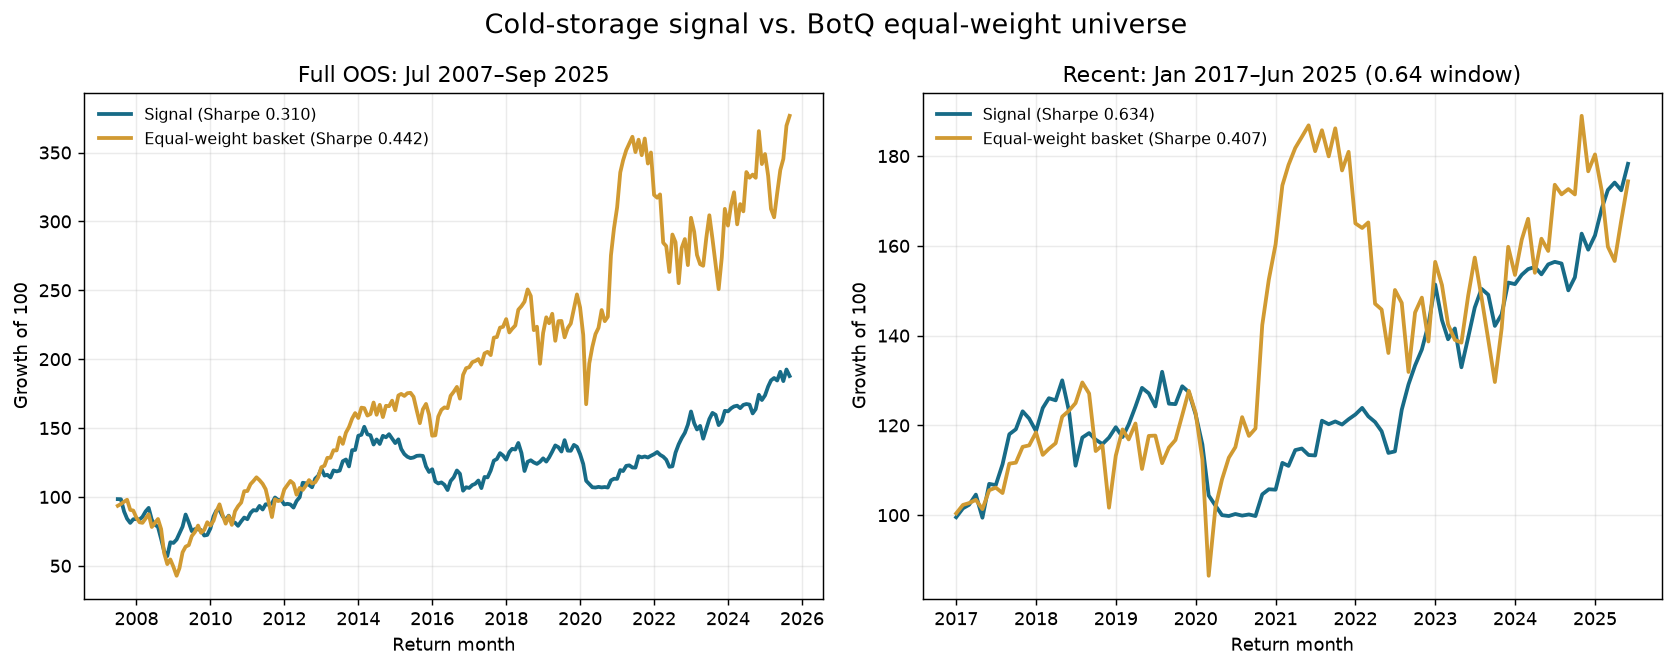

In [20]:
comparison_windows = {
    "Full OOS: Jul 2007–Sep 2025": primary.index >= pd.Period("2007-07", freq="M"),
    "Recent: Jan 2017–Jun 2025 (0.64 window)": (primary.index >= pd.Period("2017-01", freq="M")) & (primary.index <= pd.Period("2025-06", freq="M")),
}
comparison_rows = []
for window_name, mask in comparison_windows.items():
    sample = primary.loc[np.asarray(mask)]
    for label, column in [
        ("Cold-storage signal (long/short)", "strategy_return"),
        ("BotQ equal-weight universe (long only)", "universe_return"),
    ]:
        stats = performance(sample[column]).to_dict()
        stats.update({"period": window_name, "portfolio": label})
        comparison_rows.append(stats)
comparison = pd.DataFrame(comparison_rows).set_index(["period", "portfolio"])
comparison.to_csv(RESULTS / "cold_storage_signal_vs_equal_weight_comparison.csv")
comparison_display = comparison.copy()
for col in ["total_return", "annualized_return", "annualized_volatility", "max_drawdown", "positive_month_share"]:
    comparison_display[col] = comparison_display[col].map(lambda value: f"{value:.1%}")
comparison_display["sharpe_rf0"] = comparison_display["sharpe_rf0"].map(lambda value: f"{value:.3f}")
comparison_display["months"] = comparison_display["months"].astype(int)
print("Matched-period risk and return comparison")
display(comparison_display)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, (window_name, mask) in zip(axes, comparison_windows.items()):
    sample = primary.loc[np.asarray(mask)]
    signal_wealth = 100 * (1 + sample["strategy_return"]).cumprod()
    universe_wealth = 100 * (1 + sample["universe_return"]).cumprod()
    signal_sr = performance(sample["strategy_return"])["sharpe_rf0"]
    universe_sr = performance(sample["universe_return"])["sharpe_rf0"]
    ax.plot(sample.index.to_timestamp(), signal_wealth,
            label=f"Signal (Sharpe {signal_sr:.3f})", linewidth=2.1, color="#176B87")
    ax.plot(sample.index.to_timestamp(), universe_wealth,
            label=f"Equal-weight basket (Sharpe {universe_sr:.3f})", linewidth=2.1, color="#D19A32")
    ax.set_title(window_name)
    ax.set_ylabel("Growth of 100")
    ax.set_xlabel("Return month")
    ax.grid(alpha=.25)
    ax.legend(frameon=False, fontsize=9)
fig.suptitle("Cold-storage signal vs. BotQ equal-weight universe", fontsize=15)
fig.tight_layout()
plt.savefig(RESULTS / "cold_storage_signal_vs_equal_weight.png", dpi=180, bbox_inches="tight")
plt.show()

## 11. Extend the signal through December 2025

The BotQ stock file ends in September 2025. To include the latest complete calendar year, this section uses Yahoo Finance dividend-adjusted prices for TSN, CPB, and GIS through December. It recomputes the same walk-forward model from the adjusted-price history; the signal rule and portfolio weights do not change. On overlapping months, the pair returns correlate **0.999998** with BotQ pair returns, with mean absolute difference about **0.0027 percentage points per month**.

The equal-weight BotQ benchmark comparison above still ends in September because the universe file has no October–December returns. This section extends the signal only, not the broad-market comparison. [Yahoo Finance historical prices](https://finance.yahoo.com/quote/TSN/history/).


BotQ/Yahoo pair-return overlap: 308 months (2000-02–2025-09)
Correlation: 0.999998
Mean absolute difference: 0.00002724 (return units)


                                         months  ... positive_month_share
Full OOS: Jul 2007–Dec 2025                 222  ...                52.3%
Recent: Jan 2017–Jun 2025 (0.64 window)     102  ...                55.9%
Recent: Jan 2017–Sep 2025                   105  ...                55.2%
Recent: Jan 2017–Dec 2025                   108  ...                55.6%

[4 rows x 7 columns]

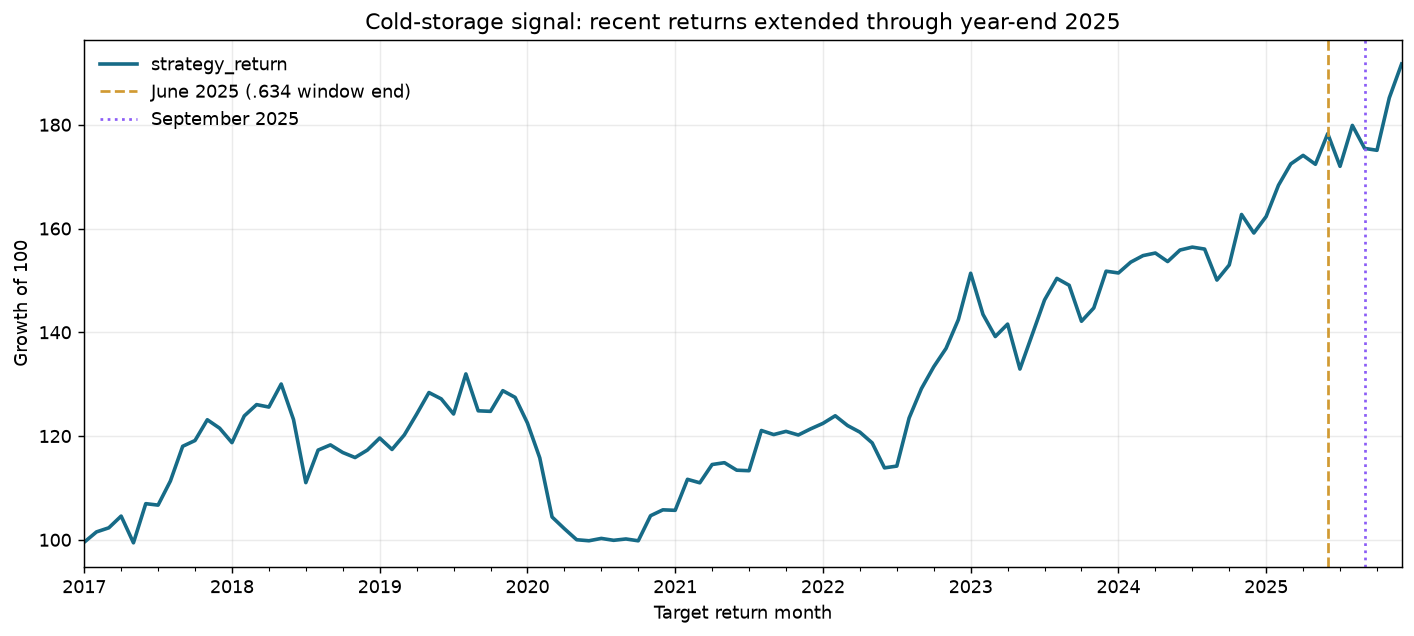

In [22]:
yahoo_monthly = pd.read_csv(DATA / "target_stocks_yahoo_monthly_returns.csv")
yahoo_monthly["month"] = pd.PeriodIndex(yahoo_monthly["month"], freq="M")
yahoo_stock_returns = yahoo_monthly.set_index("month")[ ["TSN", "CPB", "GIS"] ].sort_index()
yahoo_pair_return = 0.5 * (yahoo_stock_returns["TSN"] - 0.5 * (yahoo_stock_returns["CPB"] + yahoo_stock_returns["GIS"]))
source_check = pd.concat([
    pair_return.rename("BotQ pair return"),
    yahoo_pair_return.rename("Yahoo adjusted-price pair return"),
], axis=1).dropna()
print(f"BotQ/Yahoo pair-return overlap: {len(source_check)} months ({source_check.index.min()}–{source_check.index.max()})")
print(f"Correlation: {source_check.corr().iloc[0, 1]:.6f}")
print(f"Mean absolute difference: {source_check.diff(axis=1).iloc[:, -1].abs().mean():.8f} (return units)")

extended = walk_forward_ols(feature, yahoo_pair_return, horizon_months=2, min_train=MIN_TRAIN)
extended = extended.loc[
    (extended.index >= pd.Period("2007-07", freq="M"))
    & (extended.index <= pd.Period("2025-12", freq="M"))
].copy()
extended["position"] = np.where(extended["forecast"] >= 0, 1.0, -1.0)
extended["strategy_return"] = extended["position"] * extended["actual_pair_return"]
extended.to_csv(RESULTS / "cold_storage_year_end_extension_path.csv")

extension_windows = {
    "Full OOS: Jul 2007–Dec 2025": extended["strategy_return"],
    "Recent: Jan 2017–Jun 2025 (0.64 window)": extended.loc[(extended.index >= pd.Period("2017-01", freq="M")) & (extended.index <= pd.Period("2025-06", freq="M")), "strategy_return"],
    "Recent: Jan 2017–Sep 2025": extended.loc[(extended.index >= pd.Period("2017-01", freq="M")) & (extended.index <= pd.Period("2025-09", freq="M")), "strategy_return"],
    "Recent: Jan 2017–Dec 2025": extended.loc[extended.index >= pd.Period("2017-01", freq="M"), "strategy_return"],
}
extension_summary = pd.DataFrame({name: performance(series) for name, series in extension_windows.items()}).T
extension_summary.to_csv(RESULTS / "cold_storage_year_end_extension_metrics.csv")
shown = extension_summary.copy()
for col in ["total_return", "annualized_return", "annualized_volatility", "max_drawdown", "positive_month_share"]:
    shown[col] = shown[col].map(lambda value: f"{value:.1%}")
shown["sharpe_rf0"] = shown["sharpe_rf0"].map(lambda value: f"{value:.3f}")
shown["months"] = shown["months"].astype(int)
display(shown)

recent_path = extended.loc[extended.index >= pd.Period("2017-01", freq="M"), "strategy_return"]
recent_wealth = 100 * (1 + recent_path).cumprod()
ax = recent_wealth.plot(figsize=(11, 5), linewidth=2, color="#176B87")
ax.axvline(pd.Period("2025-06", freq="M").end_time, color="#D19A32", linestyle="--", label="June 2025 (.634 window end)")
ax.axvline(pd.Period("2025-09", freq="M").end_time, color="#8B5CF6", linestyle=":", label="September 2025")
ax.set_title("Cold-storage signal: recent returns extended through year-end 2025")
ax.set_ylabel("Growth of 100")
ax.set_xlabel("Target return month")
ax.grid(alpha=.25)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(RESULTS / "cold_storage_year_end_extension.png", dpi=180, bbox_inches="tight")
plt.show()